#### About

This file is used to make the predictions on all the splits for all 3 models. This predictions are saved in a seperate file to use for visualizations, to not recompute it all the time.

##### Data

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

with np.load("../data/bloodmnist.npz", allow_pickle=False) as dataset:
    t_images = dataset["train_images"]
    t_labels = dataset["train_labels"].reshape(-1)
    test_images = dataset["test_images"]
    test_labels = dataset["test_labels"].reshape(-1)

train_pred = pd.read_csv("../predictions/bloodmnist_train_[AUC]1.000_[ACC]0.998@resnet50_224_1.csv", header=None)
train_pred = train_pred.to_numpy()
train_pred_resnet_50 = np.argmax(train_pred[:,1:], axis=1)

test_pred = pd.read_csv("../predictions/bloodmnist_test_[AUC]0.997_[ACC]0.941@resnet50_224_1.csv", header=None)
test_pred = test_pred.to_numpy()
test_pred_resnet_50 = np.argmax(test_pred[:,1:], axis=1)

test_pred = pd.read_csv("../predictions/bloodmnist_test_[AUC]0.998_[ACC]0.966@resnet18_224_1.csv", header=None)
test_pred = test_pred.to_numpy()
test_pred_resnet_18 = np.argmax(test_pred[:,1:], axis=1)

#TODO: add ViT predictions
"""test_pred = pd.read_csv("../predictions/...", header=None)
test_pred = test_pred.to_numpy()
test_pred_vit = np.argmax(test_pred[:,1:], axis=1)"""


'test_pred = pd.read_csv("../predictions/...", header=None)\ntest_pred = test_pred.to_numpy()\ntest_pred_vit = np.argmax(test_pred[:,1:], axis=1)'

## Visualizations

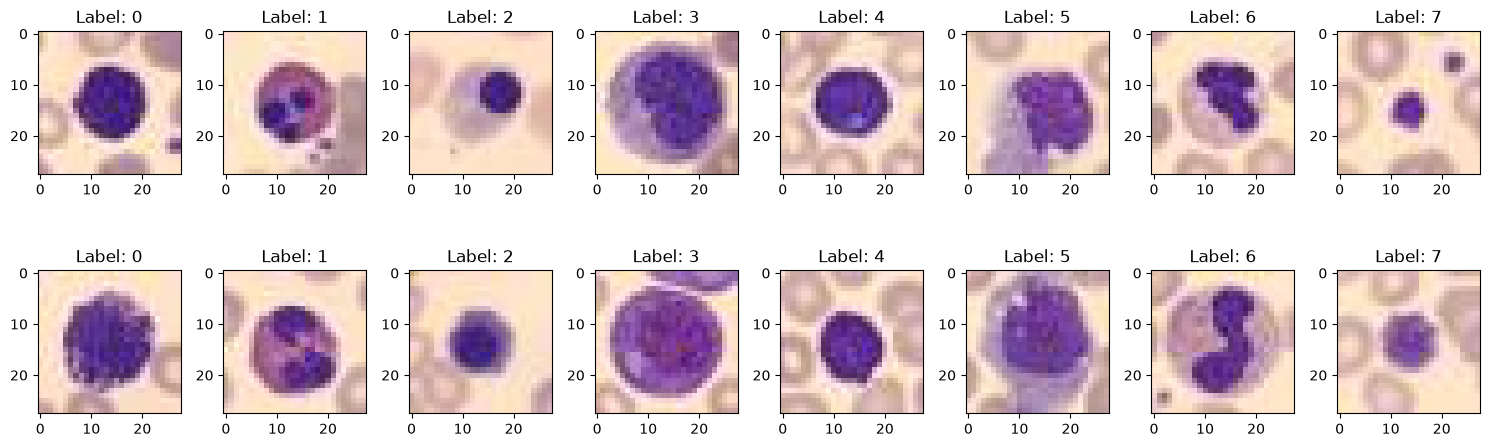

(11959, 28, 28, 3)


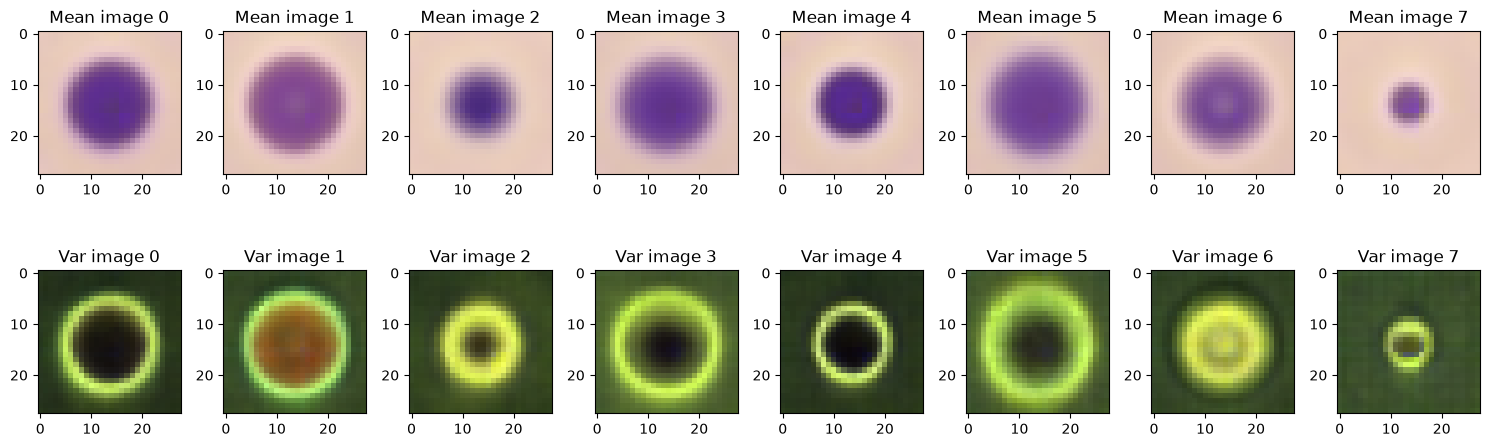

In [2]:
# sample images, mean+var, labels dist

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(8): 
    class_img = t_images[t_labels==i]
    axes[0,i].imshow(class_img[0])
    axes[0,i].title.set_text(f"Label: {i}")
    axes[1,i].imshow(class_img[1])
    axes[1,i].title.set_text(f"Label: {i}")

plt.tight_layout()
plt.show()


print(t_images.shape)

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(0,8):
    class_img = t_images[t_labels==i]
    mean_image = np.mean(class_img, axis=(0,), dtype=np.int64) 
    var_image = np.var(class_img, axis=(0,), dtype=np.int64) 
    var_image = var_image/np.max(var_image)
    axes[0,i].imshow(mean_image)
    axes[0,i].title.set_text(f"Mean image {i}")    
    axes[1,i].imshow(var_image)
    axes[1,i].title.set_text(f"Var image {i}")   

plt.tight_layout()
plt.show()


true_labels = np.bincount(test_labels)
pred_labels = np.bincount(test_pred_resnet_18)
df = pd.DataFrame({"Class": np.arange(8), "True labels": true_labels, "Predicted labels": pred_labels})
fig = px.bar(df,x="Class", y=["True labels", "Predicted labels"],barmode="group")
fig.show()

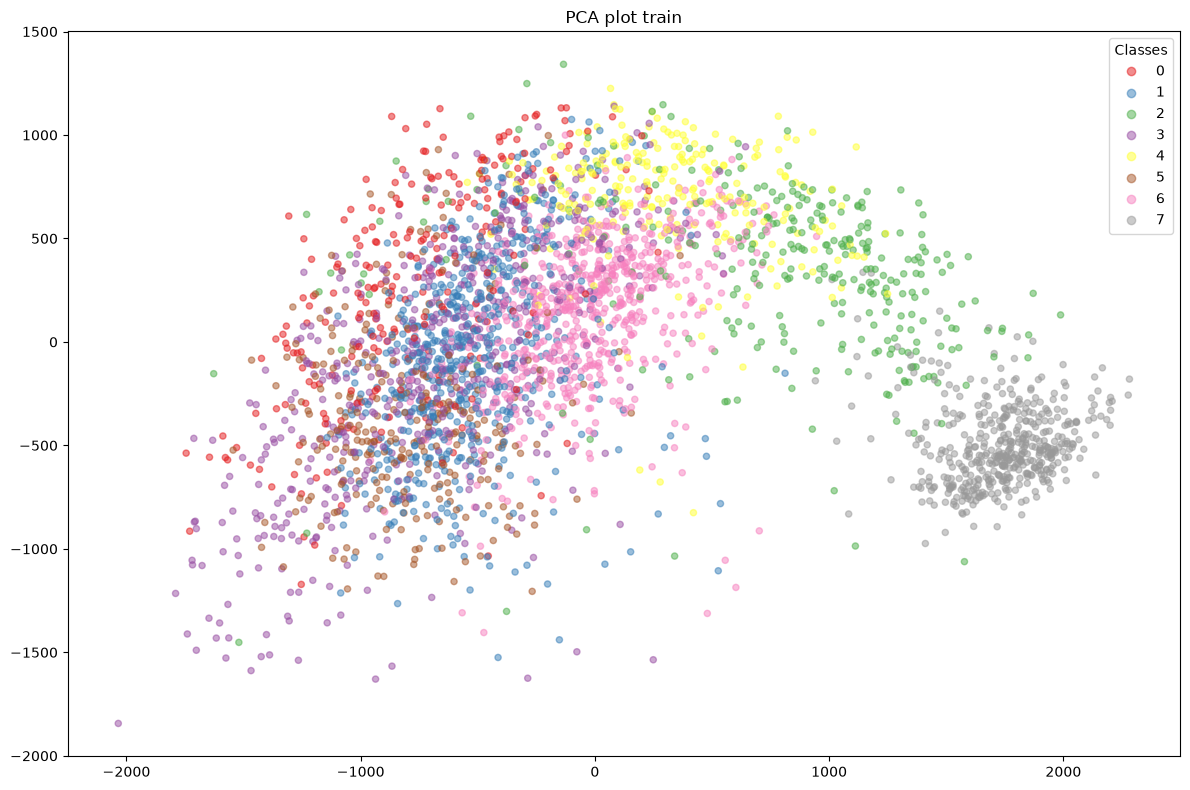

'tsvd = TruncatedSVD(n_components=2)\ntrain_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))\nprint(train_tsvd.shape, t_labels.shape)\nscatter=plt.scatter(train_tsvd[:,0], train_tsvd[:,1], c=test_labels, alpha=0.5, cmap="Set1")\nplt.title("TSVD plot train")\nhandles, labels = scatter.legend_elements()\nplt.legend(handles, labels, title="Classes")\nplt.tight_layout()\nplt.show()'

In [3]:


pca = PCA(n_components=2)
train_pca = pca.fit_transform(test_images.reshape((test_images.shape[0], -1)))
misclassified = test_labels!=test_pred_resnet_50
correctly_classified = test_labels==test_pred_resnet_50

norm = plt.Normalize(vmin=test_labels.min(), vmax=test_labels.max())
plt.figure(figsize=(12, 8))
scatter=plt.scatter(train_pca[:,0], train_pca[:,1], c=test_labels, alpha=0.5, cmap="Set1", s=20, norm=norm)

plt.title("PCA plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()

#plotly PCA with wrong predictions
colors = dict(zip(np.arange(8), px.colors.qualitative.Set1))
fig = go.Figure()

for c in np.arange(8):
    fig.add_scatter(x=train_pca[test_labels==c][:, 0], y=train_pca[test_labels==c][:, 1], mode="markers", name=str(c), legendgroup=str(c), marker=dict(color=colors[c], size=6, opacity=0.4))
    fig.add_scatter(x=train_pca[(test_labels==c) & misclassified][:, 0], y=train_pca[(test_labels==c) & misclassified][:, 1],
        mode="markers", legendgroup=str(c), showlegend=False, marker=dict(color=[colors[p] for p in test_pred_resnet_50[(test_labels==c) & misclassified]],size=10,line=dict(color=colors[c], width=2)))
fig.update_layout(title="PCA - True (outline) vs Predicted (center)", width=1000, height=700, legend=dict(groupclick="togglegroup"))
fig.show()

#plotly PCA with wrong predictions with out class coloring
fig = go.Figure()

fig.add_scatter(x=train_pca[correctly_classified][:, 0], y=train_pca[correctly_classified][:, 1], legendgroup=0, name="correct", mode="markers", marker=dict(color="green"))
fig.add_scatter(x=train_pca[misclassified][:, 0], y=train_pca[misclassified][:, 1], mode="markers", legendgroup=1, name = "misclassified", marker=dict(color="red" ,))
fig.update_layout(title="PCA - correctly vs incorrectly classified", width=1000, height=700, legend=dict(groupclick="togglegroup"))
fig.show()

"""tsne = TSNE(n_components=2, perplexity=15)
train_tnse = tsne.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tnse.shape, t_labels.shape)
scatter=plt.scatter(train_tnse[:,0], train_tnse[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSNE plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()"""

"""tsvd = TruncatedSVD(n_components=2)
train_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tsvd.shape, t_labels.shape)
scatter=plt.scatter(train_tsvd[:,0], train_tsvd[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSVD plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()"""



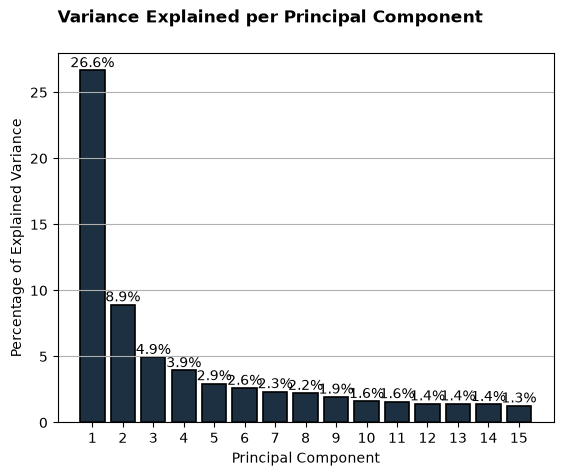

In [4]:
# using https://towardsdatascience.com/5-pca-visualizations-you-must-try-on-your-next-data-science-project-148ec3d31e4d/ 
# for input data inspection --> not useable for model behavior

pca = PCA(n_components=15)
train_pca = pca.fit(test_images.reshape((test_images.shape[0], -1)))
plot_y = [val * 100 for val in train_pca.explained_variance_ratio_]
plot_x = range(1, len(plot_y) + 1)

bars = plt.bar(plot_x, plot_y, align="center", color="#1C3041", edgecolor="#000000", linewidth=1.2)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.001, f"{yval:.1f}%", ha="center", va="bottom")

plt.xlabel("Principal Component")
plt.ylabel("Percentage of Explained Variance")
plt.title("Variance Explained per Principal Component", loc="left", fontdict={"weight": "bold"}, y=1.06)
plt.grid(axis="y")
plt.xticks(plot_x)

plt.show()

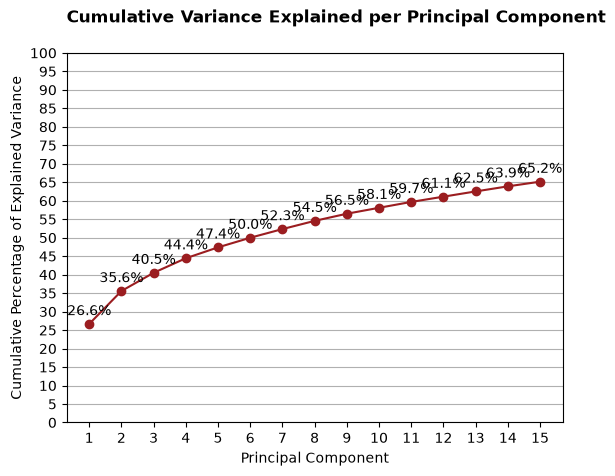

In [5]:
exp_var = [val * 100 for val in train_pca.explained_variance_ratio_]
plot_y = [sum(exp_var[:i+1]) for i in range(len(exp_var))]
plot_x = range(1, len(plot_y) + 1)

plt.plot(plot_x, plot_y, marker="o", color="#9B1D20")
for x, y in zip(plot_x, plot_y):
    plt.text(x, y + 1.5, f"{y:.1f}%", ha="center", va="bottom")

plt.xlabel("Principal Component")
plt.ylabel("Cumulative Percentage of Explained Variance")
plt.title("Cumulative Variance Explained per Principal Component", loc="left", fontdict={"weight": "bold"}, y=1.06)

plt.yticks(range(0, 101, 5))
plt.grid(axis="y")
plt.xticks(plot_x)

plt.show()

#### Confusion matrix

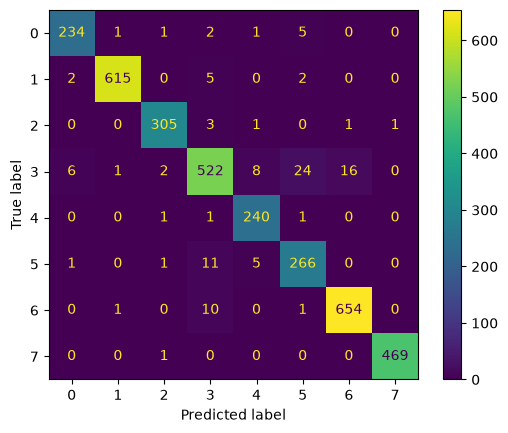

In [6]:
cm = confusion_matrix(test_labels, test_pred_resnet_18)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

#### Vision Transformer

In [ ]:
import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import ViTForImageClassification, ViTImageProcessor
from pathlib import Path
import os

torch.set_num_threads(4)

device = "cuda" if torch.cuda.is_available() else "cpu"

model_path = Path("../models/vit")
if not model_path.exists():
    raise FileNotFoundError(f"Model directory not found at: {model_path}")

print("Loading model and processor...")
processor = ViTImageProcessor.from_pretrained(model_path, local_files_only=True)
model = ViTForImageClassification.from_pretrained(model_path, local_files_only=True)
model.to(device)
model.eval()

def batch_inference(model, processor, images, batch_size=32, device="cuda"): # batched inference to avoid out-of-memory
    all_probs = []
    
    for i in range(0, len(images), batch_size):
        batch_imgs = images[i : i + batch_size]
        
        inputs = processor(images=batch_imgs, return_tensors="pt").to(device)
        
        with torch.inference_mode(), torch.amp.autocast(device_type=device, dtype=torch.float16):
            outputs = model(**inputs)
            probs = outputs.logits.softmax(dim=1).cpu().numpy()
            all_probs.append(probs)
        
        del inputs, outputs
        torch.cuda.empty_cache()
        
    return np.concatenate(all_probs, axis=0)

BATCH_SIZE = 32

print("Process train set...")
t_probs = batch_inference(model, processor, t_images, batch_size=BATCH_SIZE, device=device)

print("Process test set...")
test_probs = batch_inference(model, processor, test_images, batch_size=BATCH_SIZE, device=device)

print("Save results...")
t_df = pd.DataFrame(t_probs)
test_df = pd.DataFrame(test_probs)

t_df.to_csv("../predictions/vit_bloodmnist_train.csv", index=True, header=False)
test_df.to_csv("../predictions/vit_bloodmnist_test.csv", index=True, header=False)
print("Done!")

Done!
